# Fitting the galaxies and the cosmology to $w_p(r_p)$ alone

This notebook fits one data vector, the projected correlation function
$w_p(r_p)$ of one galaxy sample, with four parameters of the `zheng07`
occupation and two of the cosmology, $\Omega_{\rm m}$ and
$\ln(10^{10}A_{\rm s})$.
No number density, lensing or other probe enters the likelihood.
The data are a mock: the model at a known point, with a Gaussian covariance
and one noise draw, so that every step can be checked against the truth.
The steps are the model, the data and its covariance, the likelihood and its
gradient, the best fit, the Fisher matrix at it, and a Hamiltonian Monte Carlo
chain.
It runs on a `pip install` of `ggah_mod` plus `matplotlib`, `scipy`, `blackjax`
and `corner`, in about ten minutes on one CPU, most of it in the chain.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")

import jax
jax.config.update("jax_enable_x64", True)   # before the first ggah_mod import

import time
import warnings

import blackjax
import corner
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize

import ggah_mod
warnings.filterwarnings("ignore", category=ggah_mod.WorkInProgressWarning)

import ggah_mod.sectors as S
import ggah_mod.spectra as SP
from ggah_mod import DIFFERENTIABLE as BACKEND
from ggah_mod.cosmology import PLANCK18, make_pk, sigma8
from ggah_mod.covariance.gaussian import make_wp_kernel, wp_gaussian
from ggah_mod.halos.field import make_field
from ggah_mod.observables import wp

plt.rcParams.update({"figure.dpi": 90, "figure.figsize": (6.4, 4.0),
                     "axes.grid": True, "grid.alpha": 0.3})
print(f"ggah_mod {ggah_mod.__version__}, jax {jax.__version__}, blackjax {blackjax.__version__}")

ggah_mod 1.7.0, jax 0.10.2, blackjax 1.5


## The model

The chain is the one of the layer pages: a `Cosmology`, the halo field at the
sample's redshift, the galaxy sector, the galaxy auto-spectrum, and its
projection.
Only the galaxy sector is passed to `SP.spectrum`, since $P_{\rm gg}$ needs no
other.
The sample is at $z = 0.25$ and $\pi_{\max} = 60\,h^{-1}$Mpc, a property of the
measurement that `wp` takes with no default.
The twelve bins are logarithmic from 0.1 to 30 $h^{-1}$Mpc, and the model is
evaluated at their geometric centres.

`wp` compiles under `jax.jit` when the wavenumbers are concrete, so the $k$ grid
of the backend is read once, from a field at the fiducial cosmology, and passed
as a NumPy array.

In [2]:
Z, PI_MAX = 0.25, 60.0
RP_EDGES = np.logspace(-1.0, np.log10(30.0), 13)
RP = np.sqrt(RP_EDGES[1:] * RP_EDGES[:-1])

pk = make_pk("emu_pk")
gal = S.GalaxySector("zheng07", backend=BACKEND)
options = SP.PkOptions.from_backend(BACKEND)
GAL0 = S.galaxy_defaults("zheng07")
K = np.asarray(make_field(PLANCK18, BACKEND, pk, z=Z).k)

NAMES = ["Omega_m", "ln10A_s", "log10mmin", "log10m1", "alpha"]
LABELS = [r"$\Omega_{\rm m}$", r"$\ln 10^{10}A_{\rm s}$", r"$\log M_{\min}$",
          r"$\log M_1$", r"$\alpha$"]


def unpack(theta):
    """The flat parameter vector as a cosmology and a galaxy-parameter dict."""
    cosmo = PLANCK18.replace(Omega_m=theta[0], ln10A_s=theta[1])
    gal_p = dict(GAL0, log10mmin=theta[2], log10m1=theta[3], alpha=theta[4])
    return cosmo, gal_p


def spectrum(theta):
    cosmo, gal_p = unpack(theta)
    field = make_field(cosmo, BACKEND, pk, z=Z)
    p_gg = SP.spectrum(field, "galaxies", "galaxies", {"galaxies": gal},
                       {"galaxies": gal_p}, options=options)
    return field, gal_p, p_gg


def model(theta):
    """w_p at the bin centres [h^-1 Mpc]."""
    return wp(RP, (K, spectrum(theta)[2].total), pi_max=PI_MAX, backend=BACKEND)


THETA_TRUE = np.array([float(PLANCK18.Omega_m), float(PLANCK18.ln10A_s),
                       GAL0["log10mmin"], GAL0["log10m1"], GAL0["alpha"]])
for n, v in zip(NAMES, THETA_TRUE):
    print(f"{n:11s} {v:.4f}")
for n in ("sigma_logm", "log10m0"):
    print(f"{n:11s} {GAL0[n]:.4f}   (held fixed)")

Omega_m     0.3100
ln10A_s     3.0440
log10mmin   11.3500
log10m1     12.4000
alpha       1.0000
sigma_logm  0.2500   (held fixed)
log10m0     11.2000   (held fixed)


Two occupation parameters are held at their defaults.
`log10m0`, the mass below which there are no satellites, barely reaches $w_p$
when $M_0 < M_{\min}$.
`sigma_logm`, the width of the central occupation, moves $w_p$ along nearly the
same direction as $M_{\min}$ and $M_1$ together; with it free, the posterior
from $w_p$ alone is a ridge that runs to the edges of the prior.
A parameter the data cannot see only lengthens the chain.

## The mock data vector and its covariance

The covariance is the Gaussian one of {mod}`ggah_mod.covariance.gaussian`, for a
volume of $10^8\,(h^{-1}{\rm Mpc})^3$: the signal is $P_{\rm gg}$ and the noise
$1/\bar n$ of the sample.
The Gaussian term misses the connected four-point function, which dominates the
small scales, so 3 per cent of every point is added in quadrature.
A real analysis uses a jackknife or mock covariance instead, with the
correction of its inverse for the finite number of realisations.
One noise draw from this covariance, with a fixed seed, makes the data.

n_bar = 2.953e-02 (h^-1 Mpc)^-3, b_eff = 1.182
sigma / w_p: [0.03  0.03  0.03  0.03  0.031 0.033 0.035 0.039 0.045 0.055 0.074 0.116]


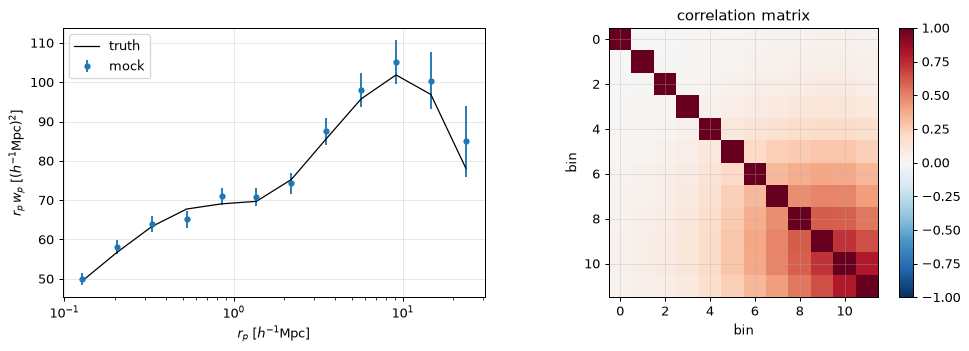

In [3]:
field0, gal_p0, P0 = spectrum(THETA_TRUE)
nbar = float(gal.number_density(field0, gal_p0))
w_true = np.asarray(model(THETA_TRUE))

VOLUME = 1e8                                     # (h^-1 Mpc)^3
kernel = make_wp_kernel(RP_EDGES, PI_MAX)
p = P0.total
cov = np.array(wp_gaussian(kernel, VOLUME, K, p, p, p, p,
                             1 / nbar, 1 / nbar, 1 / nbar, 1 / nbar))
cov += np.diag((0.03 * w_true) ** 2)
data = w_true + np.linalg.cholesky(cov) @ np.random.default_rng(1).standard_normal(RP.size)
err = np.sqrt(np.diag(cov))
icov = jnp.asarray(np.linalg.inv(cov))

print(f"n_bar = {nbar:.3e} (h^-1 Mpc)^-3, b_eff = {float(gal.effective_bias(field0, gal_p0)):.3f}")
print("sigma / w_p:", np.array2string(err / w_true, precision=3))

fig, (a0, a1) = plt.subplots(1, 2, figsize=(11.0, 4.0))
a0.errorbar(RP, RP * data, RP * err, fmt="o", ms=4, label="mock")
a0.plot(RP, RP * w_true, "k", lw=1, label="truth")
a0.set(xscale="log", xlabel=r"$r_p$ [$h^{-1}$Mpc]", ylabel=r"$r_p\,w_p$ [$(h^{-1}{\rm Mpc})^2$]")
a0.legend()
im = a1.imshow(cov / np.outer(err, err), vmin=-1, vmax=1, cmap="RdBu_r")
a1.set(title="correlation matrix", xlabel="bin", ylabel="bin")
fig.colorbar(im, ax=a1)
fig.tight_layout()

## The likelihood and its gradient

The log-posterior is $-\chi^2/2$ inside a box and $-\infty$ outside.
The box is the prior: uniform in each parameter, wide on the galaxy parameters
and inside the training range of `emu_pk` on the cosmology.
Both the $\chi^2$ and its gradient are compiled once; after that a value takes
tens of milliseconds and a gradient about a tenth of a second.
The automatic derivative is checked against a central difference.

In [4]:
LO = np.array([0.20, 2.5, 10.5, 11.5, 0.5])
HI = np.array([0.45, 3.5, 12.5, 13.5, 1.6])


@jax.jit
def chi2(theta):
    r = model(theta) - data
    return r @ icov @ r


def log_post(theta):
    inside = jnp.all((theta > LO) & (theta < HI))
    return jnp.where(inside, -0.5 * chi2(theta), -jnp.inf)


chi2_and_grad = jax.jit(jax.value_and_grad(chi2))
t0 = time.perf_counter(); chi2_and_grad(jnp.asarray(THETA_TRUE))[0].block_until_ready()
t1 = time.perf_counter(); value, grad = chi2_and_grad(jnp.asarray(THETA_TRUE + 1e-3))
grad.block_until_ready(); t2 = time.perf_counter()
print(f"compile {t1 - t0:.1f} s, then value and gradient {1e3 * (t2 - t1):.0f} ms")
print(f"chi2 at the truth = {float(chi2(jnp.asarray(THETA_TRUE))):.2f} for {RP.size} points")

g = np.asarray(chi2_and_grad(jnp.asarray(THETA_TRUE))[1])
for i in range(len(NAMES)):
    step, e = 1e-4, np.zeros(len(NAMES)); e[i] = step
    fd = (float(chi2(jnp.asarray(THETA_TRUE + e))) - float(chi2(jnp.asarray(THETA_TRUE - e)))) / (2 * step)
    print(f"{NAMES[i]:11s} autodiff {g[i]: .5e}   central difference {fd: .5e}")

compile 2.2 s, then value and gradient 110 ms


chi2 at the truth = 4.77 for 12 points
Omega_m     autodiff -4.79456e+01   central difference -4.79149e+01
ln10A_s     autodiff -4.32453e+01   central difference -4.32451e+01


log10mmin   autodiff -1.26319e+02   central difference -1.26319e+02
log10m1     autodiff  1.09904e+02   central difference  1.09903e+02
alpha       autodiff -1.95054e+02   central difference -1.95048e+02


## The best fit

L-BFGS-B, with the gradient above and the prior box as bounds, starts from a
point displaced from the truth in every parameter.

47 iterations, 7 s; chi2 = 4.10 for 12 points and 5 parameters
               truth  best fit
Omega_m       0.3100    0.3039
ln10A_s       3.0440    3.0762
log10mmin    11.3500   11.3386
log10m1      12.4000   12.3576
alpha         1.0000    0.9849


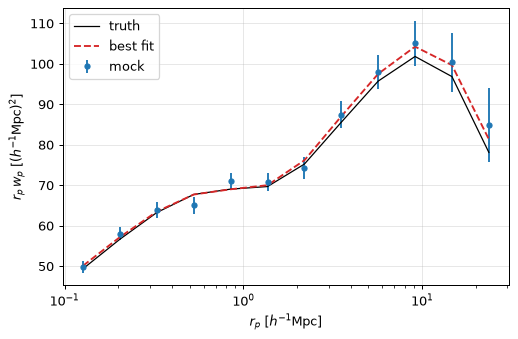

In [5]:
start = THETA_TRUE + np.array([0.03, -0.10, 0.20, 0.20, -0.10])
t0 = time.perf_counter()
res = minimize(lambda x: tuple(np.asarray(v) for v in chi2_and_grad(jnp.asarray(x))),
               start, jac=True, method="L-BFGS-B", bounds=list(zip(LO, HI)))
print(f"{res.nit} iterations, {time.perf_counter() - t0:.0f} s; chi2 = {res.fun:.2f} "
      f"for {RP.size} points and {len(NAMES)} parameters")
print(f"{'':11s}{'truth':>9s}{'best fit':>10s}")
for n, a, b in zip(NAMES, THETA_TRUE, res.x):
    print(f"{n:11s}{a:9.4f}{b:10.4f}")
theta_best = res.x

fig, ax = plt.subplots()
ax.errorbar(RP, RP * data, RP * err, fmt="o", ms=4, label="mock")
ax.plot(RP, RP * w_true, "k", lw=1, label="truth")
ax.plot(RP, RP * np.asarray(model(jnp.asarray(theta_best))), "C3--", label="best fit")
ax.set(xscale="log", xlabel=r"$r_p$ [$h^{-1}$Mpc]", ylabel=r"$r_p\,w_p$ [$(h^{-1}{\rm Mpc})^2$]")
ax.legend();

The best fit describes the data as well as the truth does, at a $\chi^2$
lower by the number of free parameters, as expected from a noise draw.
How far it may sit from the truth along each direction is what the next
section measures.

## The Fisher matrix at the best fit

With $J = \partial w_p/\partial\theta$ from one `jax.jacrev`, the Fisher matrix
of a Gaussian likelihood is $F = J^{\rm T} C^{-1} J$, and $F^{-1}$ is the
covariance of the parameters in the Gaussian approximation, without the prior.

In [6]:
J = np.asarray(jax.jit(jax.jacrev(model))(jnp.asarray(theta_best)))
F = J.T @ np.asarray(icov) @ J
pcov = np.linalg.inv(F)
sig = np.sqrt(np.diag(pcov))
corr = pcov / np.outer(sig, sig)

print(f"{'':11s}{'sigma':>9s}  correlations")
for i, n in enumerate(NAMES):
    print(f"{n:11s}{sig[i]:9.3f}  " + " ".join(f"{c: .2f}" for c in corr[i]))
evals, evecs = np.linalg.eigh(F)
print("\neigenvalues of F:", np.array2string(evals, precision=2))
print("weakest direction:", ", ".join(f"{n} {v:+.2f}" for n, v in zip(NAMES, evecs[:, 0])))

               sigma  correlations
Omega_m        0.018   1.00  0.26 -0.10 -0.17 -0.31
ln10A_s        0.456   0.26  1.00 -0.95 -0.97 -0.99
log10mmin      0.604  -0.10 -0.95  1.00  1.00  0.96
log10m1        1.064  -0.17 -0.97  1.00  1.00  0.98
alpha          0.296  -0.31 -0.99  0.96  0.98  1.00

eigenvalues of F: [5.63e-01 6.60e+01 5.35e+02 5.54e+03 1.90e+05]
weakest direction: Omega_m -0.00, ln10A_s -0.33, log10mmin +0.45, log10m1 +0.80, alpha +0.22


$\Omega_{\rm m}$ is measured by the shape of $w_p$: the turnover of the
matter spectrum, and the transition between the one- and two-halo terms.
The amplitude $\ln(10^{10}A_{\rm s})$ is anticorrelated with the occupation:
on large scales $w_p \propto b_{\rm eff}^2\sigma_8^2$, and $M_{\min}$, $M_1$
and $\alpha$ all move $b_{\rm eff}$.
The weakest direction lowers the amplitude while it raises $M_{\min}$, $M_1$
and $\alpha$: a more biased sample in a less clustered universe gives the same
$w_p$, and the shape of the one-halo term breaks the tie only in part.
The occupation also sets the number density, which is not fitted.
The number density would close it; $w_p$ alone does not.

## Sampling the posterior

The No-U-Turn sampler of `blackjax` uses the same compiled gradient.
Its mass matrix is the parameter covariance from the Fisher matrix, with the
prior box added as a Gaussian of the same width, so that the sampler moves
along the correlated directions from its first step.
With that mass matrix the step size is a fraction of one; 0.2 is used, and the mean
acceptance printed below checks it.
The chain is short, sized for this page; an analysis runs several chains,
longer, and checks $\hat R$.
Where the Fisher error exceeds the spread of the chain, the prior box, not the
data, bounds the parameter.

In [7]:
prior_prec = np.diag((np.sqrt(12.0) / (HI - LO)) ** 2)    # the box as a Gaussian
mass = np.linalg.inv(F + prior_prec)

N_SAMPLE, STEP_SIZE = 600, 0.2
t0 = time.perf_counter()
step = jax.jit(blackjax.nuts(log_post, step_size=STEP_SIZE, inverse_mass_matrix=jnp.asarray(mass),
                             max_num_doublings=4).step)
state = blackjax.nuts.init(jnp.asarray(theta_best), log_post)

key, chain, n_leap, accept = jax.random.PRNGKey(1), [], [], []
for _ in range(N_SAMPLE):
    key, sub = jax.random.split(key)
    state, info = step(sub, state)
    chain.append(np.asarray(state.position))
    n_leap.append(int(info.num_integration_steps))
    accept.append(float(info.acceptance_rate))
chain = np.array(chain)
print(f"{N_SAMPLE} samples in {time.perf_counter() - t0:.0f} s; {np.mean(n_leap):.1f} integration "
      f"steps per sample, mean acceptance {np.mean(accept):.2f}")
print(f"{'':11s}{'truth':>9s}{'mean':>9s}{'std':>9s}{'Fisher':>9s}")
for i, n in enumerate(NAMES):
    print(f"{n:11s}{THETA_TRUE[i]:9.4f}{chain[:, i].mean():9.4f}{chain[:, i].std():9.4f}{sig[i]:9.3f}")

600 samples in 549 s; 10.6 integration steps per sample, mean acceptance 0.47
               truth     mean      std   Fisher
Omega_m       0.3100   0.3002   0.0183    0.018
ln10A_s       3.0440   3.1199   0.1109    0.456
log10mmin    11.3500  11.1590   0.2717    0.604
log10m1      12.4000  12.1298   0.3262    1.064
alpha         1.0000   0.9654   0.0509    0.296


$\sigma_8$ is an output of the cosmology, so it is computed on the chain as a
derived parameter, one linear spectrum per sample.

sigma8 = 0.813 +- 0.054  (truth 0.803)


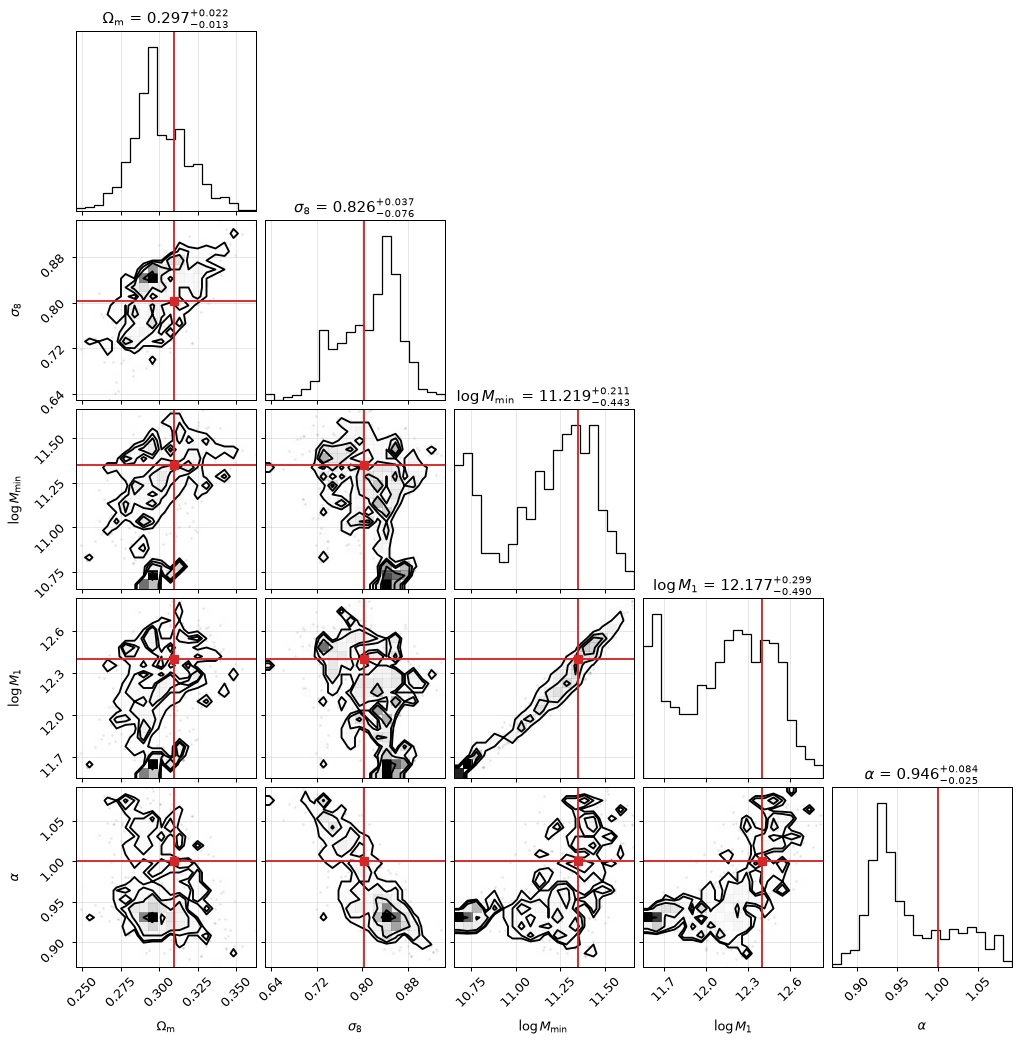

In [8]:
kk = np.logspace(-4, 2, 512)
s8_of = jax.jit(lambda om, lna: sigma8(pk.pk(kk, 0.0, PLANCK18.replace(Omega_m=om, ln10A_s=lna)), kk))
s8 = np.array([float(s8_of(om, lna)) for om, lna in chain[:, :2]])
s8_true = float(s8_of(THETA_TRUE[0], THETA_TRUE[1]))
print(f"sigma8 = {s8.mean():.3f} +- {s8.std():.3f}  (truth {s8_true:.3f})")

samples = np.column_stack([chain[:, 0], s8, chain[:, 2:]])
fig = corner.corner(samples, labels=[LABELS[0], r"$\sigma_8$"] + LABELS[2:],
                    truths=np.r_[THETA_TRUE[0], s8_true, THETA_TRUE[2:]],
                    truth_color="C3", show_titles=True, title_fmt=".3f")

## Things to try

- Add $\bar n$ as a datum, `gal.number_density(field, gal_p)` with a 5 per cent
  error, and watch the degenerate direction of the occupation close.
- Free $h$ or $n_{\rm s}$ through `PLANCK18.replace`, and read in the Fisher
  matrix which of them $w_p$ reaches beyond $\Omega_{\rm m}$.
- Change $\pi_{\max}$ in both the model and the covariance kernel, and compare
  the error on $\Omega_{\rm m}$.
- Swap `zheng07` for `zumandelbaum15`, whose parameters carry declared bounds
  (`GalaxyParams`), and use those bounds as the prior box.

Previous: {doc}`../layer3_galaxies` and its {doc}`notebook <layer3_galaxies>`.